# Shooting Method for the Blasius Boundary-Layer Equation
**AE801 Scientific Computing Lab-1 — Numerical Solution of ODEs (BVP)**

## 1. Problem statement

Steady, incompressible flow of a uniform stream $U_\infty$ over a flat plate reduces, under the similarity variable
$\eta = y\sqrt{U_\infty/(\nu x)}$ with $u/U_\infty = f'(\eta)$, to the **Blasius equation**

$$
f''' + \tfrac{1}{2} f f'' = 0, \qquad 0 < \eta < \infty,
$$

with boundary conditions

$$
f(0) = 0,\qquad f'(0) = 0 \quad(\text{no slip, no suction}),\qquad f'(\eta)\to 1 \text{ as } \eta\to\infty \quad(\text{free stream}).
$$

This is a nonlinear two-point boundary-value problem (BVP) on a semi-infinite domain. We solve it with the
**shooting method**: convert it to an initial-value problem (IVP) with one unknown initial condition, integrate with
explicit Runge–Kutta schemes (RK3 and RK4), and adjust the unknown until the far-field condition is satisfied.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from time import perf_counter

np.set_printoptions(precision=10)
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 11, "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})

## 2. Step (a) — Reduction to a first-order system

Define the state vector $Y = (y_1, y_2, y_3)^T = (f,\ f',\ f'')^T$. Then

$$
Y' = G(Y) = \begin{pmatrix} y_2 \\ y_3 \\ -\tfrac12\, y_1 y_3 \end{pmatrix}.
$$

The system is **autonomous** (no explicit $\eta$ dependence), so $G$ only needs $Y$.

In [3]:
def G(Y):
    f, fp, fpp = Y
    return np.array([fp, fpp, -0.5 * f * fpp])

## 3. Step (a) — Fixed-step Runge–Kutta integrators

**RK3 (Kutta's classical third-order scheme)**, step $h=\Delta\eta$:

$$
\begin{aligned}
k_1 &= G(Y_n), \\
k_2 &= G\!\left(Y_n + \tfrac{h}{2}k_1\right), \\
k_3 &= G\!\left(Y_n - h k_1 + 2h k_2\right), \\
Y_{n+1} &= Y_n + \tfrac{h}{6}\left(k_1 + 4k_2 + k_3\right).
\end{aligned}
$$

Local truncation error $\mathcal O(h^4)$, global error $\mathcal O(h^3)$.

**RK4 (classical fourth-order scheme)**:

$$
\begin{aligned}
k_1 &= G(Y_n), & k_2 &= G\!\left(Y_n + \tfrac{h}{2}k_1\right), \\
k_3 &= G\!\left(Y_n + \tfrac{h}{2}k_2\right), & k_4 &= G\!\left(Y_n + h k_3\right), \\
Y_{n+1} &= Y_n + \tfrac{h}{6}\left(k_1 + 2k_2 + 2k_3 + k_4\right).
\end{aligned}
$$

Global error $\mathcal O(h^4)$.

The integrator below takes $N = \eta_\infty/\Delta\eta$ steps. $\eta_\infty$ is chosen as an integer multiple of every
$\Delta\eta$ used, so the last grid point lands exactly on $\eta_\infty$ (no partial final step that would spoil the

In [4]:
def rk3_step(Y, h):
    k1 = G(Y)
    k2 = G(Y + 0.5 * h * k1)
    k3 = G(Y - h * k1 + 2.0 * h * k2)
    return Y + h / 6.0 * (k1 + 4.0 * k2 + k3)

def rk4_step(Y, h):
    k1 = G(Y)
    k2 = G(Y + 0.5 * h * k1)
    k3 = G(Y + 0.5 * h * k2)
    k4 = G(Y + h * k3)
    return Y + h / 6.0 * (k1 + 2.0 * k2 + 2.0 * k3 + k4)

STEPPERS = {"RK3": rk3_step, "RK4": rk4_step}

def integrate(s, h, eta_inf, method="RK4", store=False):
    N = int(round(eta_inf / h))
    assert abs(N * h - eta_inf) < 1e-12, "eta_inf must be an integer multiple of h"
    step = STEPPERS[method]
    Y = np.array([0.0, 0.0, s])
    if store:
        sol = np.empty((N + 1, 3)); sol[0] = Y
    for n in range(N):
        Y = step(Y, h)
        if store:
            sol[n + 1] = Y
    if store:
        return np.linspace(0.0, eta_inf, N + 1), sol
    return Y

In [5]:
def rk3_step(Y, h):
    k1 = G(Y)
    k2 = G(Y + 0.5 * h * k1)
    k3 = G(Y - h * k1 + 2.0 * h * k2)
    return Y + h / 6.0 * (k1 + 4.0 * k2 + k3)

def rk4_step(Y, h):
    k1 = G(Y)
    k2 = G(Y + 0.5 * h * k1)
    k3 = G(Y + 0.5 * h * k2)
    k4 = G(Y + h * k3)
    return Y + h / 6.0 * (k1 + 2.0 * k2 + 2.0 * k3 + k4)

STEPPERS = {"RK3": rk3_step, "RK4": rk4_step}

def integrate(s, h, eta_inf, method="RK4", store=False):
    N = int(round(eta_inf / h))
    assert abs(N * h - eta_inf) < 1e-12, "eta_inf must be an integer multiple of h"
    step = STEPPERS[method]
    Y = np.array([0.0, 0.0, s])
    if store:
        sol = np.empty((N + 1, 3)); sol[0] = Y
    for n in range(N):
        Y = step(Y, h)
        if store:
            sol[n + 1] = Y
    if store:
        return np.linspace(0.0, eta_inf, N + 1), sol
    return Y

In [6]:
def rk3_step(Y, h):
    k1 = G(Y)
    k2 = G(Y + 0.5 * h * k1)
    k3 = G(Y - h * k1 + 2.0 * h * k2)
    return Y + h / 6.0 * (k1 + 4.0 * k2 + k3)

def rk4_step(Y, h):
    k1 = G(Y)
    k2 = G(Y + 0.5 * h * k1)
    k3 = G(Y + 0.5 * h * k2)
    k4 = G(Y + h * k3)
    return Y + h / 6.0 * (k1 + 2.0 * k2 + 2.0 * k3 + k4)

STEPPERS = {"RK3": rk3_step, "RK4": rk4_step}

def integrate(s, h, eta_inf, method="RK4", store=False):
    N = int(round(eta_inf / h))
    assert abs(N * h - eta_inf) < 1e-12, "eta_inf must be an integer multiple of h"
    step = STEPPERS[method]
    Y = np.array([0.0, 0.0, s])
    if store:
        sol = np.empty((N + 1, 3)); sol[0] = Y
    for n in range(N):
        Y = step(Y, h)
        if store:
            sol[n + 1] = Y
    if store:
        return np.linspace(0.0, eta_inf, N + 1), sol
    return Y

In [7]:
def rk3_step(Y, h):
    k1 = G(Y)
    k2 = G(Y + 0.5 * h * k1)
    k3 = G(Y - h * k1 + 2.0 * h * k2)
    return Y + h / 6.0 * (k1 + 4.0 * k2 + k3)

def rk4_step(Y, h):
    k1 = G(Y)
    k2 = G(Y + 0.5 * h * k1)
    k3 = G(Y + 0.5 * h * k2)
    k4 = G(Y + h * k3)
    return Y + h / 6.0 * (k1 + 2.0 * k2 + 2.0 * k3 + k4)

STEPPERS = {"RK3": rk3_step, "RK4": rk4_step}

def integrate(s, h, eta_inf, method="RK4", store=False):
    N = int(round(eta_inf / h))
    assert abs(N * h - eta_inf) < 1e-12, "eta_inf must be an integer multiple of h"
    step = STEPPERS[method]
    Y = np.array([0.0, 0.0, s])
    if store:
        sol = np.empty((N + 1, 3)); sol[0] = Y
    for n in range(N):
        Y = step(Y, h)
        if store:
            sol[n + 1] = Y
    if store:
        return np.linspace(0.0, eta_inf, N + 1), sol
    return Y

In [8]:
def check_order(stepper, hs, T=1.0):
    errs = []
    for h in hs:
        Y = np.array([1.0, 1.0, 1.0])
        for _ in range(int(round(T / h))):
            Gl = lambda Z: np.array([Z[1], Z[2], Z[0]])
            if stepper == "RK3":
                k1 = Gl(Y); k2 = Gl(Y + 0.5*h*k1); k3 = Gl(Y - h*k1 + 2*h*k2)
                Y = Y + h/6*(k1 + 4*k2 + k3)
            else:
                k1 = Gl(Y); k2 = Gl(Y + 0.5*h*k1); k3 = Gl(Y + 0.5*h*k2); k4 = Gl(Y + h*k3)
                Y = Y + h/6*(k1 + 2*k2 + 2*k3 + k4)
        errs.append(abs(Y[0] - np.e))
    return np.array(errs)

hs = np.array([0.1, 0.05, 0.025, 0.0125])
for m in ("RK3", "RK4"):
    e = check_order(m, hs)
    print(f"{m}: error ratios = {np.round(e[:-1]/e[1:], 2)}  -> observed order ≈ {np.round(np.log2(e[:-1]/e[1:]), 3)}")

RK3: error ratios = [7.69 7.84 7.92]  -> observed order ≈ [2.942 2.971 2.986]
RK4: error ratios = [15.35 15.67 15.83]  -> observed order ≈ [3.94  3.97  3.985]


 schemes show their design order on a smooth linear test problem, so the implementations are correct.

## 4. Step (b) — Missing initial condition and the shooting parameter

At $\eta = 0$ two conditions are known, $f(0)=0$ and $f'(0)=0$. The third initial condition, the **wall shear
parameter $f''(0)$**, is unknown; instead a condition is given at $\eta\to\infty$. We introduce the shooting parameter

$$
s = f''(0), \qquad Y(0) = (0,\ 0,\ s)^T,
$$

and look for the value of $s$ for which the IVP solution satisfies $f'(\eta)\to 1$.

Physically, $f''(0)$ is proportional to the wall shear stress, $\tau_w = \mu U_\infty \sqrt{U_\infty/(\nu x)}\, f''(0)$.

## 5. Step (c) — Choice of $\eta_\infty$ and the residual

The far-field condition is imposed at a finite truncation point $\eta_\infty$:

$$
F(s;\eta_\infty) = f'(\eta_\infty; s) - 1 = 0 .
$$

### 5.1 Shape of the residual

First, let us look at $F(s)$ over a range of $s$ to see whether it has a single, well-behaved root.

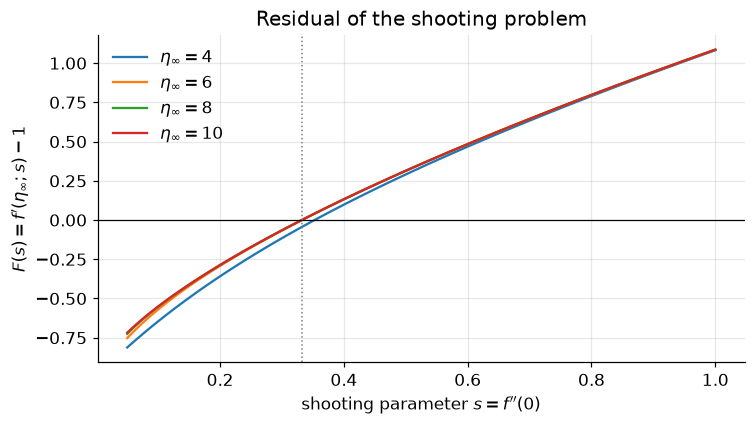

In [9]:
s_grid = np.linspace(0.05, 1.0, 120)
fig, ax = plt.subplots(figsize=(7, 4))
for eta_inf in (4.0, 6.0, 8.0, 10.0):
    F = [integrate(s, 0.05, eta_inf, "RK4")[1] - 1.0 for s in s_grid]
    ax.plot(s_grid, F, label=fr"$\eta_\infty = {eta_inf:g}$")
ax.axhline(0, color="k", lw=0.8)
ax.axvline(0.332, color="grey", ls=":", lw=1)
ax.set_xlabel(r"shooting parameter $s = f''(0)$")
ax.set_ylabel(r"$F(s) = f'(\eta_\infty; s) - 1$")
ax.set_title("Residual of the shooting problem")
ax.legend()
plt.tight_layout(); plt.show()

$F(s)$ is smooth and monotonically increasing, with a single root near $s\approx0.33$. A bracket such as
$[0.1,\ 0.5]$ is therefore safe for bisection, and a secant iteration started from two points in that range converges
reliably.

**Why the curves cross zero at the same $s$ only for large $\eta_\infty$:** for small $\eta_\infty$ (e.g. 4) the
boundary layer has not yet reached the free stream, so forcing $f'(4)=1$ over-estimates $s$.

### 5.2 Sensitivity of $s$ to $\eta_\infty$

We solve the shooting problem (very fine RK4 step, so time-stepping error is negligible) for increasing $\eta_\infty$.
The root finder is defined in Section 6 but used here for convenience.

In [10]:
def secant(F, s0, s1, tol=1e-12, maxit=50):
    # Secant iteration. Stops when |Δs| < tol and |F| < tol. Returns (root, iterations, history).
    F0, F1 = F(s0), F(s1)
    hist = [(s0, F0), (s1, F1)]
    for k in range(1, maxit + 1):
        s2 = s1 - F1 * (s1 - s0) / (F1 - F0)
        F2 = F(s2)
        hist.append((s2, F2))
        if abs(s2 - s1) < tol and abs(F2) < tol:
            return s2, k, hist
        s0, F0, s1, F1 = s1, F1, s2, F2
    raise RuntimeError("secant did not converge")

def bisection(F, a, b, tol=1e-12, maxit=200):
    Fa, Fb = F(a), F(b)
    assert Fa * Fb < 0, "root not bracketed"
    hist = []
    for k in range(1, maxit + 1):
        c = 0.5 * (a + b); Fc = F(c)
        hist.append((c, Fc))
        if 0.5 * (b - a) < tol or Fc == 0:
            return c, k, hist
        if Fa * Fc < 0: b, Fb = c, Fc
        else:           a, Fa = c, Fc
    raise RuntimeError("bisection did not converge")

def shoot(h, eta_inf, method="RK4", tol=1e-12, s0=0.1, s1=0.5):
    F = lambda s: integrate(s, h, eta_inf, method)[1] - 1.0
    return secant(F, s0, s1, tol)

print(f"{'eta_inf':>8} {'s = f\'\'(0)':>16} {'change':>12}")
prev = None
eta_list = [3, 4, 5, 6, 7, 8, 9, 10, 12, 15]
s_vs_eta = []
for eta_inf in eta_list:
    s, _, _ = shoot(0.0025, float(eta_inf), "RK4")
    s_vs_eta.append(s)
    print(f"{eta_inf:8d} {s:16.12f} {'' if prev is None else f'{s-prev:12.2e}'}")
    prev = s

 eta_inf       s = f''(0)       change
       3   0.404549710598 
       4   0.352746253459    -5.18e-02
       5   0.336152343905    -1.66e-02
       6   0.332565931204    -3.59e-03
       7   0.332096357855    -4.70e-04
       8   0.332059191735    -3.72e-05
       9   0.332057390779    -1.80e-06
      10   0.332057337204    -5.36e-08
      12   0.332057336215    -9.88e-10
      15   0.332057336215    -7.50e-14


In [11]:
def secant(F, s0, s1, tol=1e-12, maxit=50):
    # Secant iteration. Stops when |Δs| < tol and |F| < tol. Returns (root, iterations, history).
    F0, F1 = F(s0), F(s1)
    hist = [(s0, F0), (s1, F1)]
    for k in range(1, maxit + 1):
        s2 = s1 - F1 * (s1 - s0) / (F1 - F0)
        F2 = F(s2)
        hist.append((s2, F2))
        if abs(s2 - s1) < tol and abs(F2) < tol:
            return s2, k, hist
        s0, F0, s1, F1 = s1, F1, s2, F2
    raise RuntimeError("secant did not converge")

def bisection(F, a, b, tol=1e-12, maxit=200):
    Fa, Fb = F(a), F(b)
    assert Fa * Fb < 0, "root not bracketed"
    hist = []
    for k in range(1, maxit + 1):
        c = 0.5 * (a + b); Fc = F(c)
        hist.append((c, Fc))
        if 0.5 * (b - a) < tol or Fc == 0:
            return c, k, hist
        if Fa * Fc < 0: b, Fb = c, Fc
        else:           a, Fa = c, Fc
    raise RuntimeError("bisection did not converge")

def shoot(h, eta_inf, method="RK4", tol=1e-12, s0=0.1, s1=0.5):
    F = lambda s: integrate(s, h, eta_inf, method)[1] - 1.0
    return secant(F, s0, s1, tol)

print(f"{'eta_inf':>8} {'s = f\'\'(0)':>16} {'change':>12}")
prev = None
eta_list = [3, 4, 5, 6, 7, 8, 9, 10, 12, 15]
s_vs_eta = []
for eta_inf in eta_list:
    s, _, _ = shoot(0.0025, float(eta_inf), "RK4")
    s_vs_eta.append(s)
    print(f"{eta_inf:8d} {s:16.12f} {'' if prev is None else f'{s-prev:12.2e}'}")
    prev = s

 eta_inf       s = f''(0)       change
       3   0.404549710598 
       4   0.352746253459    -5.18e-02
       5   0.336152343905    -1.66e-02
       6   0.332565931204    -3.59e-03
       7   0.332096357855    -4.70e-04
       8   0.332059191735    -3.72e-05
       9   0.332057390779    -1.80e-06
      10   0.332057337204    -5.36e-08
      12   0.332057336215    -9.88e-10
      15   0.332057336215    -7.50e-14


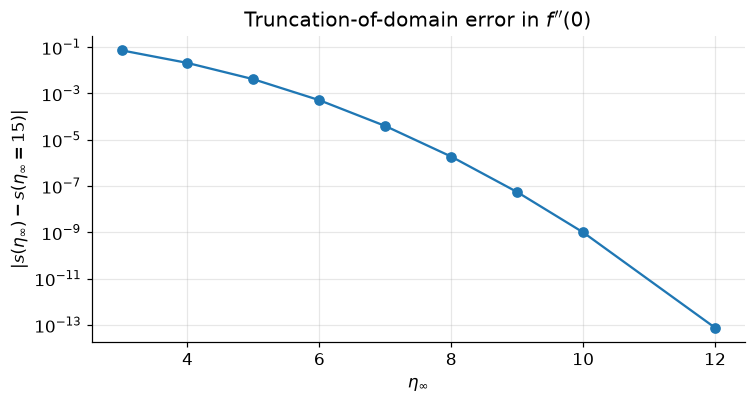

In [12]:
fig, ax = plt.subplots(figsize=(7, 3.8))
s_ref_far = s_vs_eta[-1]
ax.semilogy(eta_list[:-1], np.abs(np.array(s_vs_eta[:-1]) - s_ref_far), "o-")
ax.set_xlabel(r"$\eta_\infty$")
ax.set_ylabel(r"$|s(\eta_\infty) - s(\eta_\infty=15)|$")
ax.set_title(r"Truncation-of-domain error in $f''(0)$")
plt.tight_layout(); plt.show()

The domain-truncation error decays roughly like a Gaussian in $\eta_\infty$ (the approach of $f'$ to 1 is
$\sim e^{-(\eta-\beta)^2/4}$). At $\eta_\infty = 10$ it is about $10^{-9}$, and by $\eta_\infty=12$ it reaches
round-off level. A $10^{-9}$ shift is six orders of magnitude below the 3-digit target. Also, it does **not** affect
the order-of-accuracy study, because the reference solution in Section 7 uses the same $\eta_\infty$, so this error
cancels out of $|s-s_{\rm ref}|$.

**Choice:** $\eta_\infty = 10$. It is also an exact multiple of every step size in the study
($10/0.4 = 25$, …, $10/0.025 = 400$), so every run ends exactly at $\eta_\infty$.

In [13]:
ETA_INF = 10.0
TOL = 1e-12

## 6. Step (c) — Root finding and tolerance

Three root finders were considered:

* **Bisection** — guaranteed convergence on a bracket, linear rate (one binary digit per iteration).
* **Secant** — superlinear (order $\approx1.618$), needs no derivative; one IVP solve per iteration.
* **Newton** — quadratic, but needs $dF/ds = \partial f'(\eta_\infty)/\partial s$, obtained by integrating the
  variational equations alongside the Blasius system. Implemented below for comparison.

**Tolerance.** We stop when both $|s_{k+1}-s_k| < 10^{-12}$ and $|F(s_{k+1})| < 10^{-12}$. This is several orders
of magnitude below the smallest discretization error in the study (RK4 at $\Delta\eta = 0.025$ gives errors around
$10^{-9}$), so the root-finding error never contaminates the order-of-accuracy measurement, while still being well
above double-precision round-off ($\sim10^{-16}$).

### 6.1 Newton's method with variational equations

Let $Z = \partial Y/\partial s = (z_1, z_2, z_3)^T$. Differentiating $Y' = G(Y)$ with respect to $s$:

$$
Z' = J(Y)\,Z,\qquad J = \begin{pmatrix} 0 & 1 & 0\\ 0 & 0 & 1\\ -\tfrac12 y_3 & 0 & -\tfrac12 y_1\end{pmatrix},
\qquad Z(0) = (0,0,1)^T,
$$

and $F'(s) = z_2(\eta_\infty)$. The 6-component augmented system is integrated with the same RK scheme.

In [14]:
def G_aug(W):
    f, fp, fpp, z1, z2, z3 = W
    return np.array([fp, fpp, -0.5 * f * fpp,
                     z2, z3, -0.5 * (fpp * z1 + f * z3)])

def integrate_aug(s, h, eta_inf, method="RK4"):
    N = int(round(eta_inf / h))
    W = np.array([0.0, 0.0, s, 0.0, 0.0, 1.0])
    for _ in range(N):
        if method == "RK3":
            k1 = G_aug(W); k2 = G_aug(W + 0.5*h*k1); k3 = G_aug(W - h*k1 + 2*h*k2)
            W = W + h/6*(k1 + 4*k2 + k3)
        else:
            k1 = G_aug(W); k2 = G_aug(W + 0.5*h*k1); k3 = G_aug(W + 0.5*h*k2); k4 = G_aug(W + h*k3)
            W = W + h/6*(k1 + 2*k2 + 2*k3 + k4)
    return W

def newton(h, eta_inf, method="RK4", s=0.5, tol=1e-12, maxit=50):
    hist = []
    for k in range(1, maxit + 1):
        W = integrate_aug(s, h, eta_inf, method)
        F, dF = W[1] - 1.0, W[4]
        s_new = s - F / dF
        hist.append((s_new, F))
        if abs(s_new - s) < tol:
            return s_new, k, hist
        s = s_new
    raise RuntimeError("Newton did not converge")

### 6.2 Comparison of the three root finders (RK4, $\Delta\eta = 0.05$, $\eta_\infty=10$)

In [15]:
h_demo = 0.05
F_demo = lambda s: integrate(s, h_demo, ETA_INF, "RK4")[1] - 1.0

t = perf_counter(); s_b, it_b, hb = bisection(F_demo, 0.1, 0.5, TOL); tb = perf_counter() - t
t = perf_counter(); s_s, it_s, hs_ = secant(F_demo, 0.1, 0.5, TOL); ts = perf_counter() - t
t = perf_counter(); s_n, it_n, hn = newton(h_demo, ETA_INF, "RK4", 0.5, TOL); tn = perf_counter() - t

print(f"{'method':<10}{'s = f\'\'(0)':>18}{'iterations':>12}{'time [s]':>10}")
for name, sv, it, tt in [("bisection", s_b, it_b, tb), ("secant", s_s, it_s, ts), ("Newton", s_n, it_n, tn)]:
    print(f"{name:<10}{sv:18.13f}{it:12d}{tt:10.3f}")

method            s = f''(0)  iterations  time [s]
bisection    0.3320573377576          39     0.469
secant       0.3320573377572           6     0.098
Newton       0.3320573377572           5     0.054


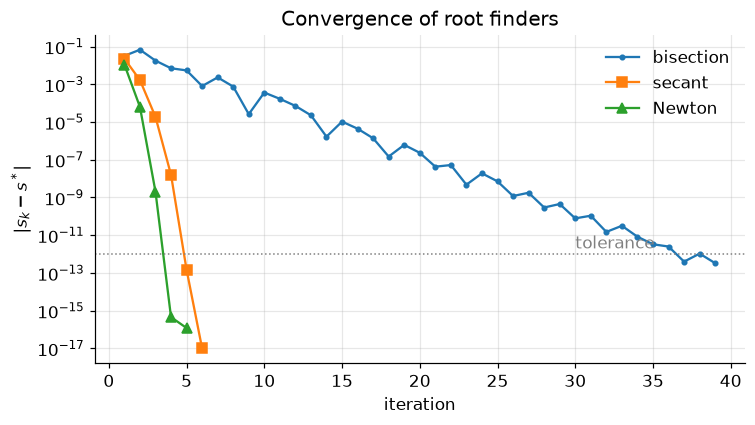

In [16]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogy(range(1, len(hb)+1), [abs(x - s_s) + 1e-17 for x, _ in hb], "o-", ms=3, label="bisection")
ax.semilogy(range(1, len(hs_)-1), [abs(x - s_s) + 1e-17 for x, _ in hs_[2:]], "s-", label="secant")
ax.semilogy(range(1, len(hn)+1), [abs(x - s_s) + 1e-17 for x, _ in hn], "^-", label="Newton")
ax.axhline(TOL, color="grey", ls=":", lw=1); ax.text(30, TOL*2, "tolerance", color="grey")
ax.set_xlabel("iteration"); ax.set_ylabel(r"$|s_k - s^*|$")
ax.set_title("Convergence of root finders")
ax.legend(); plt.tight_layout(); plt.show()

All three converge to the same root. Bisection needs ~40 IVP solves; secant needs fewer than 10 and Newton a handful
(though each Newton step integrates a 6-component system). **The secant method is used for the remainder of the
report** — it is derivative-free, fast and robust for this monotone residual.

## 7. Step (d) — RK3: step-size study and order of accuracy

We compute $s$ for $\Delta\eta = 0.4,\ 0.2,\ 0.1,\ 0.05,\ 0.025$ with $\eta_\infty = 10$.

**Reference value.** To isolate the time-stepping error, the error is measured against a reference computed with
the **same $\eta_\infty$** but a much finer RK4 step ($\Delta\eta = 0.00125$), whose own error is $\sim10^{-14}$.
This way the domain-truncation error cancels and only the $\Delta\eta$-dependence remains.

The observed order between successive step sizes is

$$
p = \frac{\ln\left(e_{\Delta\eta}/e_{\Delta\eta/2}\right)}{\ln 2}.
$$

In [17]:
s_ref, _, _ = shoot(0.00125, ETA_INF, "RK4", TOL)
print(f"Reference s (RK4, Δη = 0.00125, η∞ = {ETA_INF:g}):  s_ref = {s_ref:.14f}")

dEtas = np.array([0.4, 0.2, 0.1, 0.05, 0.025])

def step_study(method):
    rows = []
    for h in dEtas:
        s, it, _ = shoot(h, ETA_INF, method, TOL)
        rows.append((h, s, it, abs(s - s_ref)))
    rows = np.array(rows)
    err = rows[:, 3]
    p = np.r_[np.nan, np.log(err[:-1] / err[1:]) / np.log(2)]
    print(f"\n{method}   (η∞ = {ETA_INF:g}, secant tol = {TOL:g})")
    print(f"{'Δη':>7}{'N steps':>9}{'s = f\'\'(0)':>18}{'iters':>7}{'|s - s_ref|':>14}{'order p':>10}")
    for (h, s, it, e), pp in zip(rows, p):
        print(f"{h:7.3f}{int(round(ETA_INF/h)):9d}{s:18.13f}{int(it):7d}{e:14.3e}{'' if np.isnan(pp) else f'{pp:10.3f}'}")
    return rows, p

rk3_rows, rk3_p = step_study("RK3")

Reference s (RK4, Δη = 0.00125, η∞ = 10):  s_ref = 0.33205733720370

RK3   (η∞ = 10, secant tol = 1e-12)
     Δη  N steps        s = f''(0)  iters   |s - s_ref|   order p
  0.400       25   0.3319771447702      6     8.019e-05
  0.200       50   0.3320495982485      6     7.739e-06     3.373
  0.100      100   0.3320565334009      6     8.038e-07     3.267
  0.050      200   0.3320572475919      6     8.961e-08     3.165
  0.025      400   0.3320573267010      6     1.050e-08     3.093


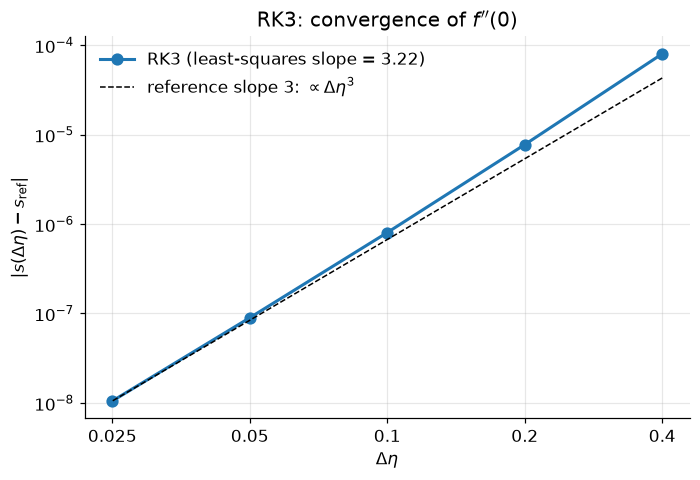

RK3 global slope from least-squares fit: 3.223


In [18]:
def loglog_plot(rows, method, order, color):
    h, err = rows[:, 0], rows[:, 3]
    slope, intercept = np.polyfit(np.log(h), np.log(err), 1)
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    ax.loglog(h, err, "o-", color=color, lw=2, ms=7, label=f"{method} (least-squares slope = {slope:.2f})")
    ref = err[-1] * (h / h[-1]) ** order
    ax.loglog(h, ref, "k--", lw=1, label=fr"reference slope {order}: $\propto\Delta\eta^{order}$")
    ax.set_xticks(dEtas, [f"{v:g}" for v in dEtas]); ax.minorticks_off(); ax.set_xlabel(r"$\Delta\eta$"); ax.set_ylabel(r"$|s(\Delta\eta) - s_{\rm ref}|$")
    ax.set_title(f"{method}: convergence of $f''(0)$")
    ax.legend(); plt.tight_layout(); plt.show()
    return slope

slope_rk3 = loglog_plot(rk3_rows, "RK3", 3, "tab:blue")
print(f"RK3 global slope from least-squares fit: {slope_rk3:.3f}")

**Observation.** The error in $f''(0)$ falls by a factor close to 8 each time $\Delta\eta$ is halved, and the
log–log plot is a straight line of slope $\approx 3$, confirming RK3's **third-order** global accuracy. At the
coarsest step ($\Delta\eta=0.4$) the solution is not yet fully in the asymptotic range, so the first local order
deviates slightly from 3.

## 8. Step (e) — Solution profiles (RK3)

Profiles from the finest RK3 run ($\Delta\eta = 0.025$).

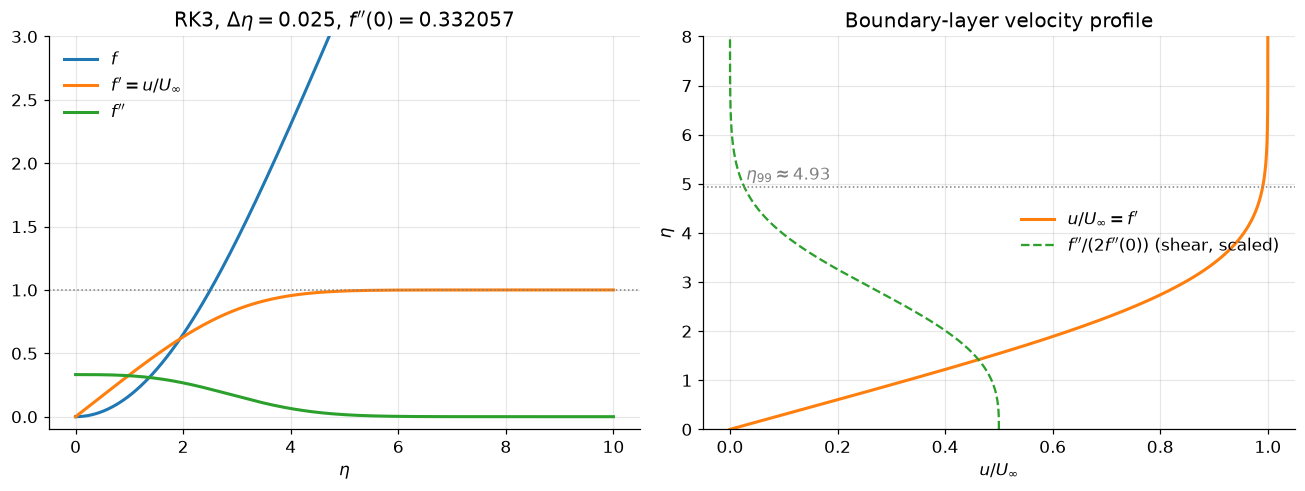

In [20]:
def plot_profiles(method, h, s, color_set=("tab:blue", "tab:orange", "tab:green")):
    eta, Y = integrate(s, h, ETA_INF, method, store=True)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
    ax = axes[0]
    ax.plot(eta, Y[:, 0], color=color_set[0], lw=2, label=r"$f$")
    ax.plot(eta, Y[:, 1], color=color_set[1], lw=2, label=r"$f'=u/U_\infty$")
    ax.plot(eta, Y[:, 2], color=color_set[2], lw=2, label=r"$f''$")
    ax.axhline(1, color="grey", ls=":", lw=1)
    ax.set_xlabel(r"$\eta$"); ax.set_ylim(-0.1, 3.0)
    ax.set_title(fr"{method}, $\Delta\eta={h}$, $f''(0)={s:.6f}$")
    ax.legend(loc="upper left")

    ax = axes[1]   # classic boundary-layer view: velocity profile, eta vertical
    ax.plot(Y[:, 1], eta, color=color_set[1], lw=2, label=r"$u/U_\infty = f'$")
    ax.plot(Y[:, 2] / s * 0.5, eta, color=color_set[2], lw=1.5, ls="--", label=r"$f''/(2f''(0))$ (shear, scaled)")
    i99 = np.argmax(Y[:, 1] >= 0.99)
    ax.axhline(eta[i99], color="grey", ls=":", lw=1)
    ax.text(0.03, eta[i99] + 0.15, fr"$\eta_{{99}}\approx{eta[i99]:.2f}$", color="grey")
    ax.set_ylim(0, 8); ax.set_xlabel(r"$u/U_\infty$"); ax.set_ylabel(r"$\eta$")
    ax.set_title("Boundary-layer velocity profile")
    ax.legend(loc="center right")
    plt.tight_layout(); plt.show()
    return eta, Y
s_rk3_fine = rk3_rows[-1, 1]
eta3, Y3 = plot_profiles("RK3", 0.025, s_rk3_fine)

**Physical interpretation**

* $f'$ (the velocity $u/U_\infty$) rises from 0 at the wall and approaches 1 smoothly; the far-field condition is met
  with no overshoot.
* $f''$ (shear) is maximum at the wall and decays rapidly to zero — the boundary layer has a finite effective thickness.
* $f$ becomes linear, $f \approx \eta - \beta$, for large $\eta$; the offset $\beta$ is the displacement-thickness
  constant ($\delta^* = \beta\sqrt{\nu x/U_\infty}$, $\beta\approx1.7208$).

The plots also show the effect of step size: below, the RK3 profiles for all step sizes are overlaid.